In [1]:
import scipy.io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from pathlib import Path

from scipy.fft import rfft, rfftfreq
from scipy.signal import butter, filtfilt

In [2]:
dataset_path = Path("../dataset")
def load_signal(filename):

    file_path = dataset_path / filename

    data = scipy.io.loadmat(file_path)

    signal_key = [
        key for key in data.keys()
        if key.endswith("_DE_time")
    ][0]

    signal = data[signal_key].flatten()

    return signal
normal_signal = load_signal("100.mat")
inner_signal = load_signal("105.mat")
ball_signal = load_signal("118.mat")
outer_signal = load_signal("130.mat")

print("Normal signal length:", len(normal_signal))
print("Inner fault signal length:", len(inner_signal))
print("Ball fault signal length:", len(ball_signal))
print("Outer fault signal length:", len(outer_signal))

Normal signal length: 485643
Inner fault signal length: 121265
Ball fault signal length: 122571
Outer fault signal length: 121991


In [3]:
fs = 12000

sampling_interval = 1 / fs

nyquist_frequency = fs / 2

print("Sampling frequency:", fs, "Hz")
print("Sampling interval:", sampling_interval, "seconds")
print("Nyquist frequency:", nyquist_frequency, "Hz")

Sampling frequency: 12000 Hz
Sampling interval: 8.333333333333333e-05 seconds
Nyquist frequency: 6000.0 Hz


In [5]:
def calculate_fft(signal, fs):

    segment_size = 2048

    segment = signal[:segment_size]

    # Remove DC component
    segment = segment - np.mean(segment)

    # Apply Hann window
    window = np.hanning(segment_size)

    windowed_signal = segment * window

    # Calculate FFT
    fft_values = np.abs(rfft(windowed_signal))

    # Frequency axis
    frequencies = rfftfreq(segment_size, d=1/fs)

    # Normalize amplitude
    amplitude = 2 * fft_values / np.sum(window)

    return frequencies, amplitude

In [7]:
normal_freq, normal_fft = calculate_fft(normal_signal, fs)

inner_freq, inner_fft = calculate_fft(inner_signal, fs)

ball_freq, ball_fft = calculate_fft(ball_signal, fs)

outer_freq, outer_fft = calculate_fft(outer_signal, fs)

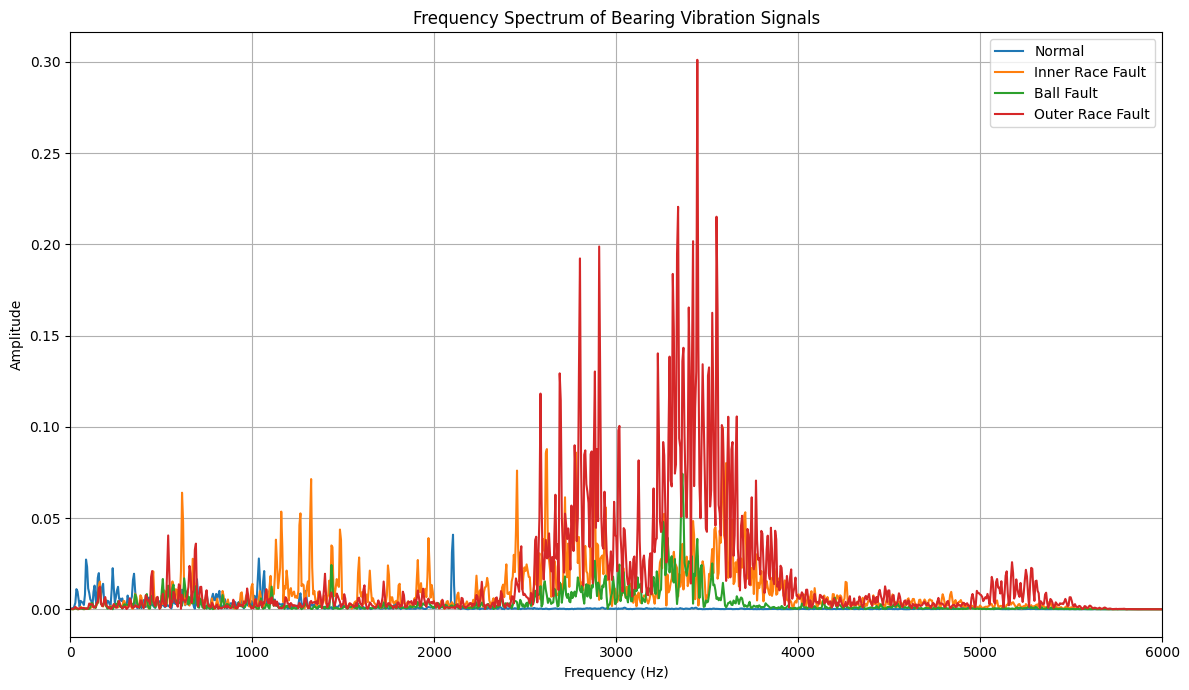

In [8]:
plt.figure(figsize=(12, 7))

plt.plot(normal_freq, normal_fft, label="Normal")

plt.plot(inner_freq, inner_fft, label="Inner Race Fault")

plt.plot(ball_freq, ball_fft, label="Ball Fault")

plt.plot(outer_freq, outer_fft, label="Outer Race Fault")

plt.title("Frequency Spectrum of Bearing Vibration Signals")

plt.xlabel("Frequency (Hz)")

plt.ylabel("Amplitude")

plt.xlim(0, 6000)

plt.legend()

plt.grid()

plt.tight_layout()

plt.show()

In [9]:
from scipy.signal import find_peaks

In [10]:
def find_dominant_frequencies(frequencies, amplitude):

    peaks, properties = find_peaks(
        amplitude,
        prominence=0.005,
        distance=5
    )

    peak_amplitudes = amplitude[peaks]
    peak_frequencies = frequencies[peaks]

    # Sort peaks by amplitude
    sorted_indices = np.argsort(peak_amplitudes)[::-1]

    top_indices = sorted_indices[:10]

    result = pd.DataFrame({
        "Frequency (Hz)": peak_frequencies[top_indices],
        "Amplitude": peak_amplitudes[top_indices]
    })

    return result

In [11]:
print("NORMAL BEARING")
print(find_dominant_frequencies(normal_freq, normal_fft))

print("\nINNER RACE FAULT")
print(find_dominant_frequencies(inner_freq, inner_fft))

print("\nBALL FAULT")
print(find_dominant_frequencies(ball_freq, ball_fft))

print("\nOUTER RACE FAULT")
print(find_dominant_frequencies(outer_freq, outer_fft))

NORMAL BEARING
   Frequency (Hz)  Amplitude
0     2103.515625   0.040849
1     1037.109375   0.027816
2       87.890625   0.027230
3      234.375000   0.022499
4     1066.406250   0.020931
5      158.203125   0.019801
6      351.562500   0.019455
7      697.265625   0.016458
8      263.671875   0.012306
9       35.156250   0.011023

INNER RACE FAULT
   Frequency (Hz)  Amplitude
0     3585.937500   0.099554
1     2619.140625   0.087764
2     2777.343750   0.085975
3     2876.953125   0.078141
4     2455.078125   0.075998
5     1324.218750   0.071344
6      615.234375   0.063864
7     2718.750000   0.061361
8     2941.406250   0.055907
9     1160.156250   0.053509

BALL FAULT
   Frequency (Hz)  Amplitude
0     3363.281250   0.074281
1     3257.812500   0.047888
2     3445.312500   0.038551
3     3304.687500   0.029073
4     3416.015625   0.028972
5     2882.812500   0.026565
6     3527.343750   0.025126
7     3017.578125   0.024480
8     1435.546875   0.024271
9     3222.656250   0.02075

In [12]:
print("Maximum FFT amplitudes:")

print("Normal:", np.max(normal_fft))
print("Inner:", np.max(inner_fft))
print("Ball:", np.max(ball_fft))
print("Outer:", np.max(outer_fft))

Maximum FFT amplitudes:
Normal: 0.040848768569438004
Inner: 0.0995543166683242
Ball: 0.07428068793363737
Outer: 0.3011133685899079


In [13]:
print("Maximum detected peak amplitudes:")

print("Normal:",
      find_dominant_frequencies(normal_freq, normal_fft)["Amplitude"].max())

print("Inner:",
      find_dominant_frequencies(inner_freq, inner_fft)["Amplitude"].max())

print("Ball:",
      find_dominant_frequencies(ball_freq, ball_fft)["Amplitude"].max())

print("Outer:",
      find_dominant_frequencies(outer_freq, outer_fft)["Amplitude"].max())

Maximum detected peak amplitudes:
Normal: 0.040848768569438004
Inner: 0.0995543166683242
Ball: 0.07428068793363737
Outer: 0.3011133685899079


In [14]:
from scipy.signal import butter, sosfiltfilt

In [15]:
# Filter parameters
cutoff_frequency = 5000
filter_order = 4

# Design Butterworth low-pass filter
sos = butter(
    filter_order,
    cutoff_frequency,
    btype="low",
    fs=fs,
    output="sos"
)

# Apply filter to all four original signals
normal_filtered = sosfiltfilt(sos, normal_signal)

inner_filtered = sosfiltfilt(sos, inner_signal)

ball_filtered = sosfiltfilt(sos, ball_signal)

outer_filtered = sosfiltfilt(sos, outer_signal)

print("Butterworth filtering completed!")

Butterworth filtering completed!


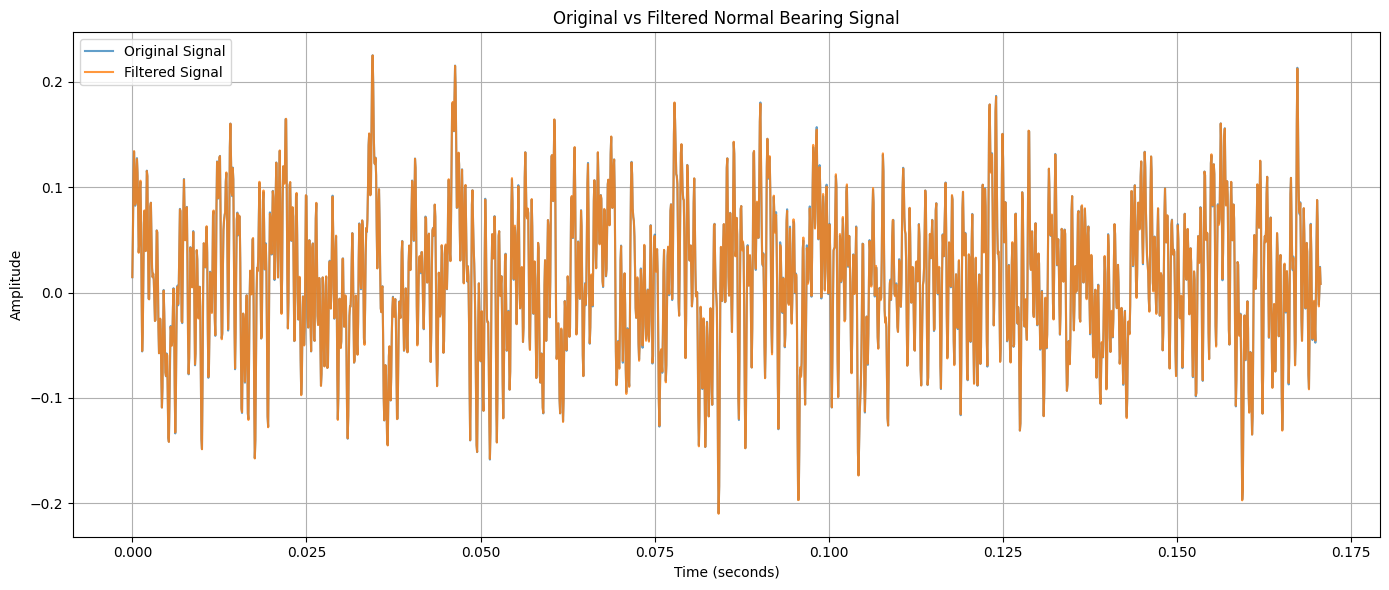

In [16]:
plt.figure(figsize=(14, 6))

time = np.arange(2048) / fs

plt.plot(
    time,
    normal_signal[:2048],
    label="Original Signal",
    alpha=0.7
)

plt.plot(
    time,
    normal_filtered[:2048],
    label="Filtered Signal",
    alpha=0.8
)

plt.title("Original vs Filtered Normal Bearing Signal")

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

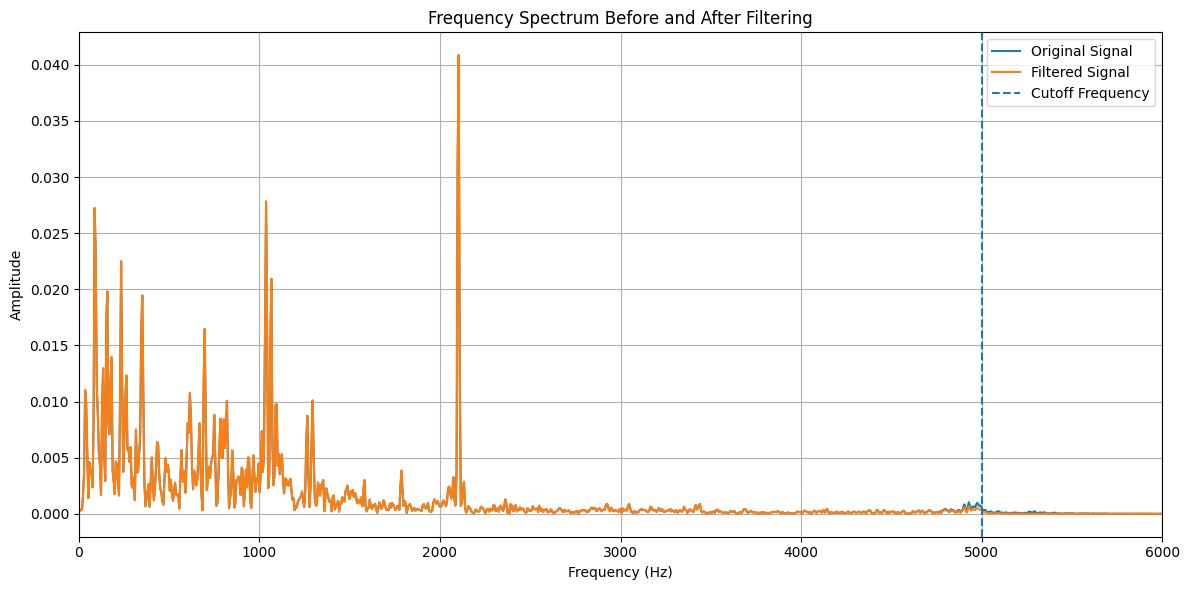

In [17]:
original_freq, original_fft = calculate_fft(
    normal_signal, fs
)

filtered_freq, filtered_fft = calculate_fft(
    normal_filtered, fs
)

plt.figure(figsize=(12, 6))

plt.plot(
    original_freq,
    original_fft,
    label="Original Signal"
)

plt.plot(
    filtered_freq,
    filtered_fft,
    label="Filtered Signal"
)

plt.axvline(
    cutoff_frequency,
    linestyle="--",
    label="Cutoff Frequency"
)

plt.title("Frequency Spectrum Before and After Filtering")

plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")

plt.xlim(0, 6000)

plt.legend()
plt.grid()

plt.tight_layout()
plt.show()